Start: prediction 2.0, error -8.0, loss 64.0
Hand gradient at start: dL/dw = 2*(2-10)*2 = -32, dL/db = -16

lr = 0.05:
  step  0: loss 64.00000000 | w 1.0000 | b 0.0000
  step 10: loss 0.00006104 | w 4.1969 | b 1.5984
  step 20: loss 0.00000000 | w 4.2000 | b 1.6000
  step 30: loss 0.00000000 | w 4.2000 | b 1.6000
  step 40: loss 0.00000000 | w 4.2000 | b 1.6000
  step 50: loss 0.00000000 | w 4.2000 | b 1.6000


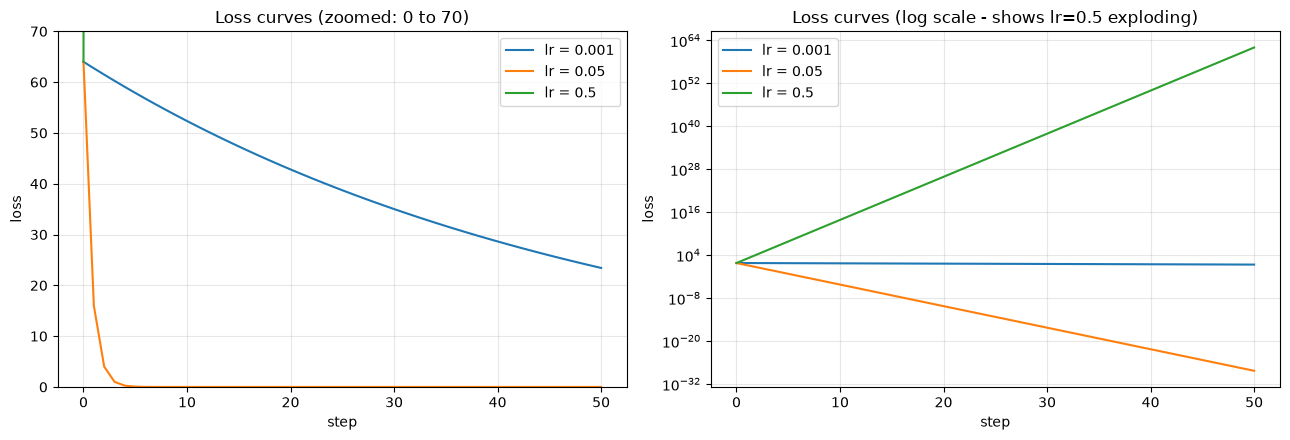

lr = 0.001: loss after 50 steps = 23.43
lr = 0.05 : loss after 50 steps = 5.049e-29
lr = 0.5  : loss after 50 steps = 1.028e+62


In [1]:
import numpy as np
import matplotlib.pyplot as plt

x, t = 2.0, 10.0

# ---- Hand gradient at the start (chain rule) ----
w, b = 1.0, 0.0
e = w * x + b - t
print(f"Start: prediction {w*x+b}, error {e}, loss {e**2}")
print(f"Hand gradient at start: dL/dw = 2*({w*x+b:.0f}-{t:.0f})*{x:.0f} = {2*e*x:.0f}, dL/db = {2*e:.0f}")

# ---- Gradient descent ----
def gradient_descent(lr, steps=50, verbose=False):
    w, b = 1.0, 0.0
    losses = []
    for step in range(steps + 1):
        e = w * x + b - t          # forward pass: error
        loss = e ** 2
        losses.append(loss)
        if verbose and step % 10 == 0:
            print(f"  step {step:>2}: loss {loss:.8f} | w {w:.4f} | b {b:.4f}")
        dw = 2 * e * x             # backward pass: chain rule
        db = 2 * e
        w -= lr * dw               # update: subtract the gradient
        b -= lr * db
    return losses

print("\nlr = 0.05:")
losses_main = gradient_descent(0.05, verbose=True)

# ---- Compare 3 learning rates ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lr in [0.001, 0.05, 0.5]:
    L = gradient_descent(lr)
    axes[0].plot(L, label=f"lr = {lr}")
    axes[1].plot(L, label=f"lr = {lr}")
axes[0].set_ylim(0, 70)
axes[0].set_title("Loss curves (zoomed: 0 to 70)")
axes[1].set_yscale("log")
axes[1].set_title("Loss curves (log scale - shows lr=0.5 exploding)")
for ax in axes:
    ax.set_xlabel("step")
    ax.set_ylabel("loss")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gd_learning_rates.png", dpi=150)
plt.show()

for lr in [0.001, 0.05, 0.5]:
    print(f"lr = {lr:<5}: loss after 50 steps = {gradient_descent(lr)[-1]:.4g}")

In [2]:
%pip install torch

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
    --------------------------------------- 2.9/124.1 MB 18.9 MB/s eta 0:00:07
   - -------------------------------------- 4.2/124.1 MB 12.9 MB/s eta 0:00:10
   - -------------------------------------- 5.8/124.1 MB 10.1 MB/s eta 0:00:12
   -- ------------------------------------- 6.6/124.1 MB 8.5 MB/s eta 0:00:14
   -- ------------------------------------- 7.6/124.1 MB 7.9 MB/s eta 0:00:15
   -- ------------------------------------- 8.4/124.1 MB 7.4 MB/s eta 0:00:16
   -- ------------------------------------- 8.9/124.1 MB 6.4 MB/s eta 0:00:19
   -- ------------------------------------- 9.2/124.1 MB 5.7 MB/s eta 0:00:21
   --- ------------------------------------ 9.4/124.1 MB 5.3 MB/s eta 0:00:22
   --- ------------------------------------ 9.7/124.1 MB 5.0 MB/s eta 0:00:24
   --- ------------------------------------ 10.2/124.1 MB 4.5 MB/s eta 0:00:26
   --- ------------------------------------ 10.7/124.1 MB 4.3 MB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


### Results
- Hand gradient at start: e = 1*2 + 0 - 10 = -8, L = 64; dL/dw = 2*e*x = 2*(2-10)*2 = -32, dL/db = 2*e = -16.
- lr = 0.05: loss falls from 64.0 to 0.0 within ~20 steps (w -> 4.2, b -> 1.6, so 4.2*2 + 1.6 = 10).
- lr = 0.001: too small - loss still 23.4 after 50 steps (slow).
- lr = 0.5: too large - loss explodes 64 -> 1024 -> 16384 ... (diverges). Chart: gd_learning_rates.png.

### What is a gradient and why do we subtract it?
1. The gradient is the slope of the loss with respect to each weight: how much the loss changes if that weight changes a little.
2. Its sign shows the direction in which the loss increases; its size shows how steeply.
3. Subtracting it (w = w - lr * gradient) moves each weight in the direction that decreases the loss - like walking downhill.
4. The learning rate sets the step size: too small is slow, too large overshoots the minimum and the loss diverges.

### Batch size and epochs
- **Batch size:** the number of training examples used to compute one gradient and make one weight update. Small batches give noisier but more frequent updates; large batches give smoother updates but need more memory.
- **Epoch:** one full pass through the whole training set. With 1,000 examples and batch size 50, one epoch = 20 updates; training usually runs for many epochs.

##Task 2-Optimisers and regularisation

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

torch.manual_seed(42)

# ---- Data: 1000 points, 80% train / 20% validation ----
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_tr  = torch.tensor(X_tr,  dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_tr  = torch.tensor(y_tr,  dtype=torch.float32).unsqueeze(1)    # shape (800, 1)
y_val = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
print("Train:", X_tr.shape, " Validation:", X_val.shape)

# ---- Model: 2 inputs -> 64 -> 64 -> 1 output ----
def make_model(regularised=False):
    if regularised:      # with BatchNorm + Dropout
        return nn.Sequential(
            nn.Linear(2, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1))
    return nn.Sequential(
        nn.Linear(2, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 1))

loss_fn = nn.BCEWithLogitsLoss()      # sigmoid + binary cross-entropy in one, numerically safe

# ---- Training loop ----
def train(model, optimizer, epochs=100, batch_size=32, patience=None, scheduler=None):
    train_losses, val_losses, lrs = [], [], []
    best_val, wait, best_state = float("inf"), 0, None
    for epoch in range(epochs):
        model.train()                                   # Dropout/BatchNorm in training mode
        perm = torch.randperm(len(X_tr))                # shuffle every epoch
        total = 0.0
        for i in range(0, len(X_tr), batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()                       # 1. clear old gradients
            loss = loss_fn(model(X_tr[idx]), y_tr[idx]) # 2. forward pass + loss
            loss.backward()                             # 3. backpropagation (chain rule)
            optimizer.step()                            # 4. update weights
            total += loss.item() * len(idx)
        train_losses.append(total / len(X_tr))

        model.eval()                                    # Dropout off, BatchNorm uses running stats
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        val_losses.append(val_loss)

        lrs.append(optimizer.param_groups[0]["lr"])
        if scheduler:
            scheduler.step()

        if patience:                                    # early stopping
            if val_loss < best_val - 1e-4:
                best_val, wait = val_loss, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:
                    print(f"  Early stopping at epoch {epoch + 1} (best val loss {best_val:.4f})")
                    break
    if best_state:
        model.load_state_dict(best_state)               # restore the best weights
    return train_losses, val_losses, lrs

def accuracy(model, X_, y_):
    model.eval()
    with torch.no_grad():
        return ((model(X_) > 0).float() == y_).float().mean().item()

Train: torch.Size([800, 2])  Validation: torch.Size([200, 2])


SGD             final train loss 0.142 | val loss 0.088 | val accuracy 0.980
SGD + momentum  final train loss 0.138 | val loss 0.080 | val accuracy 0.965
Adam            final train loss 0.132 | val loss 0.074 | val accuracy 0.975


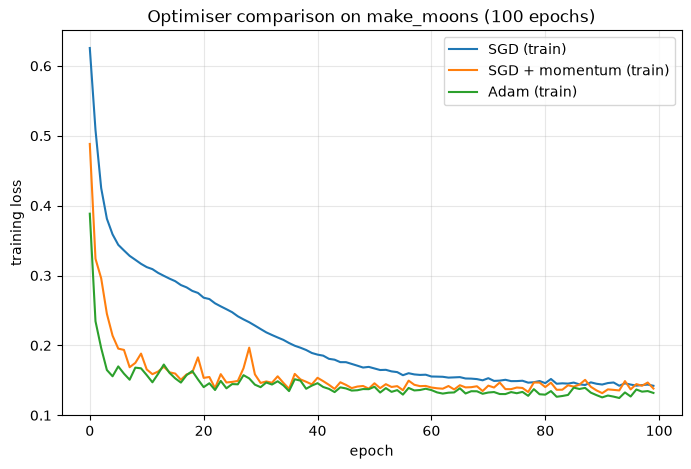

In [4]:
results = {}
for name in ["SGD", "SGD + momentum", "Adam"]:
    torch.manual_seed(42)                   # same starting weights for a fair comparison
    model = make_model()
    if name == "SGD":
        opt = torch.optim.SGD(model.parameters(), lr=0.05)
    elif name == "SGD + momentum":
        opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=0.01)
    tr, va, _ = train(model, opt, epochs=100)
    results[name] = (tr, va)
    print(f"{name:<15} final train loss {tr[-1]:.3f} | val loss {va[-1]:.3f} | "
          f"val accuracy {accuracy(model, X_val, y_val):.3f}")

plt.figure(figsize=(8, 5))
for name, (tr, va) in results.items():
    plt.plot(tr, label=f"{name} (train)")
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.title("Optimiser comparison on make_moons (100 epochs)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("optimiser_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Plain network              best val loss 0.067 (epoch 174) | final val loss 0.075 | val accuracy 0.975
Dropout(0.3) + BatchNorm   best val loss 0.087 (epoch 176) | final val loss 0.097 | val accuracy 0.965


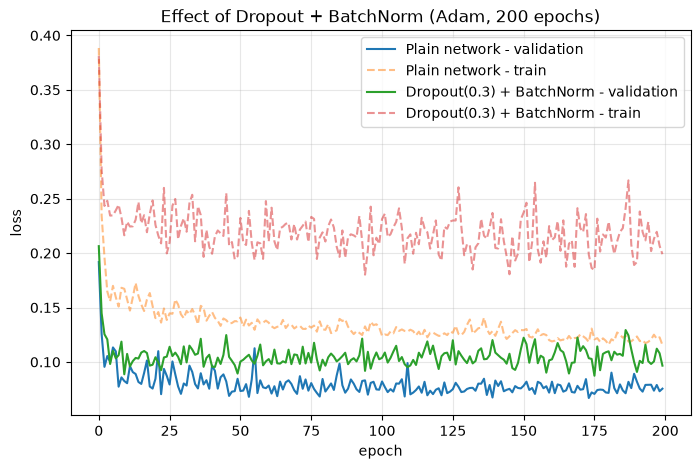

In [5]:
reg_results = {}
for name, regularised in [("Plain network", False), ("Dropout(0.3) + BatchNorm", True)]:
    torch.manual_seed(42)
    model = make_model(regularised)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    tr, va, _ = train(model, opt, epochs=200)
    reg_results[name] = (tr, va)
    print(f"{name:<26} best val loss {min(va):.3f} (epoch {int(np.argmin(va)) + 1}) | "
          f"final val loss {va[-1]:.3f} | val accuracy {accuracy(model, X_val, y_val):.3f}")

plt.figure(figsize=(8, 5))
for name, (tr, va) in reg_results.items():
    plt.plot(va, label=f"{name} - validation")
    plt.plot(tr, "--", alpha=0.5, label=f"{name} - train")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Effect of Dropout + BatchNorm (Adam, 200 epochs)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("regularisation_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

  Early stopping at epoch 18 (best val loss 0.0773)
Trained 18 epochs instead of 300 | best val loss 0.077 | val accuracy 0.985
StepLR: val accuracy 0.985 | lr went from 0.01 to 0.00125


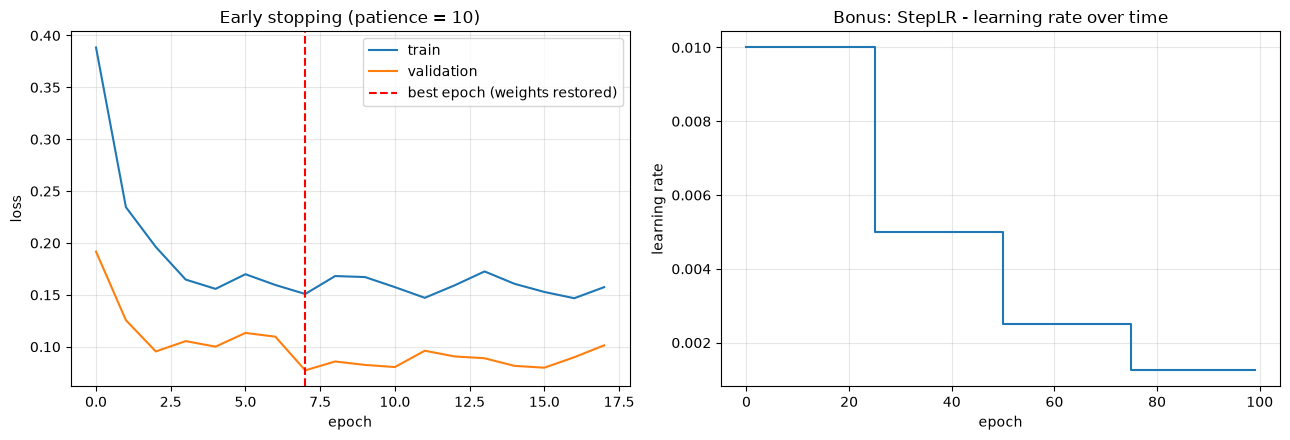

In [6]:
# ---- Early stopping (patience = 10), up to 300 epochs ----
torch.manual_seed(42)
model_es = make_model()
opt = torch.optim.Adam(model_es.parameters(), lr=0.01)
tr_es, va_es, _ = train(model_es, opt, epochs=300, patience=10)
print(f"Trained {len(va_es)} epochs instead of 300 | best val loss {min(va_es):.3f} | "
      f"val accuracy {accuracy(model_es, X_val, y_val):.3f}")

# ---- Bonus: StepLR - halve the learning rate every 25 epochs ----
torch.manual_seed(42)
model_lr = make_model()
opt = torch.optim.Adam(model_lr.parameters(), lr=0.01)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=25, gamma=0.5)
tr_lr, va_lr, lrs = train(model_lr, opt, epochs=100, scheduler=sched)
print(f"StepLR: val accuracy {accuracy(model_lr, X_val, y_val):.3f} | "
      f"lr went from {lrs[0]} to {lrs[-1]}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tr_es, label="train")
axes[0].plot(va_es, label="validation")
axes[0].axvline(int(np.argmin(va_es)), color="red", linestyle="--", label="best epoch (weights restored)")
axes[0].set_title("Early stopping (patience = 10)")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[1].step(range(len(lrs)), lrs, where="post")
axes[1].set_title("Bonus: StepLR - learning rate over time")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("learning rate")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig("early_stopping_steplr.png", dpi=150)
plt.show()

### Results
- Optimisers (100 epochs, optimiser_loss_curves.png): plain SGD falls slowest; SGD + momentum and Adam reach low loss within ~10-20 epochs. Momentum is faster but noisier; Adam is fast and smooth.
- Dropout(0.3) + BatchNorm (regularisation_val_loss.png): the plain network's validation loss rises again after its minimum (overfitting); with Dropout + BatchNorm validation loss stays lower and flatter. Best val loss: plain [ ] vs regularised [ ].
- Early stopping (patience 10): stopped after [ ] of 300 epochs and restored the best weights (early_stopping_steplr.png).
- Bonus StepLR: learning rate halved every 25 epochs (0.01 -> 0.005 -> 0.0025 -> 0.00125).

### Adam vs AdamW
1. Both adapt the step size for each weight using running averages of past gradients.
2. "Weight decay" shrinks weights a little every step to stop them growing too large (a regulariser). In Adam, weight decay is added to the gradient, so Adam's adaptive scaling also rescales it and the decay works unevenly.
3. AdamW applies weight decay directly to the weights, separately from the gradient step, so regularisation works as intended - it usually generalises better and is the default for modern networks (e.g. transformers).

### Hyperparameter table
| Hyperparameter | Too high | Too low |
|---|---|---|
| **Learning rate** | Overshoots the minimum; loss jumps around or diverges (lr = 0.5 in Task 1) | Very slow training; may stop before reaching a good solution (lr = 0.001 in Task 1) |
| **Batch size** | Smooth but fewer updates per epoch, needs more memory, can generalise worse | Very noisy gradients, unstable loss, slow per epoch (many small updates) |
| **Epochs** | Overfitting: training loss keeps falling while validation loss rises | Underfitting: the model has not learned the pattern yet |
| **Weight decay** | Weights pushed too close to zero; model too simple (underfits) | Little regularisation; large weights and overfitting |